# B-splines, P-splines and Duchon splines

Most smooths penalize the integrated squared second derivative of the function. The
[`BSpline`][pymgcv.basis_functions.BSpline],
[`PSpline`][pymgcv.basis_functions.PSpline] and
[`DuchonSpline`][pymgcv.basis_functions.DuchonSpline] bases allow choosing a different
penalty. This mostly matters where there is little or no data, where the fit is
determined by the penalty rather than by the data. This example shows how the penalty
affects predictions beyond the data, for smooths of one and of two variables.

## B-splines and P-splines

[`BSpline`][pymgcv.basis_functions.BSpline] penalizes the integrated squared
derivatives of the orders given in `penalty_orders`, while
[`PSpline`][pymgcv.basis_functions.PSpline] penalizes the differences of order
`penalty_order` between neighbouring coefficients. In both cases, the default order is
2 for cubic splines. We simulate data for $x$ between 0 and 0.7, predict up to 1, and
compare the default penalty with a first order penalty.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pymgcv.basis_functions import BSpline, DuchonSpline, PSpline
from pymgcv.gam import GAM
from pymgcv.terms import S

rng = np.random.default_rng(1)
x = rng.uniform(0, 0.7, 150)
y = np.sin(2 * np.pi * x) + rng.normal(scale=0.2, size=len(x))
data = pd.DataFrame({"x": x, "y": y})

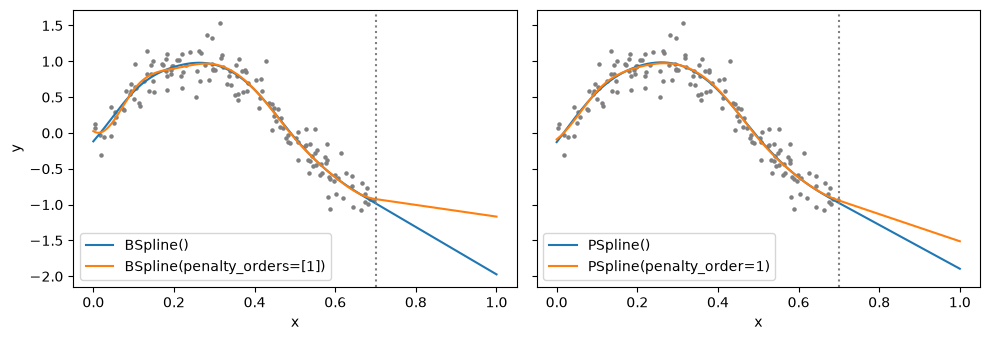

In [2]:
bases = [
    {
        "BSpline()": BSpline(),
        "BSpline(penalty_orders=[1])": BSpline(penalty_orders=[1]),
    },
    {"PSpline()": PSpline(), "PSpline(penalty_order=1)": PSpline(penalty_order=1)},
]

x_grid = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, models in zip(axes, bases, strict=True):
    ax.scatter(x, y, s=5, color="grey")
    for name, basis in models.items():
        gam = GAM({"y": S("x", bs=basis)}).fit(data)
        ax.plot(x_grid, gam.predict({"x": x_grid})["y"], label=name)
    ax.axvline(0.7, color="grey", linestyle=":")
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("y")
fig.tight_layout()
plt.show()

Where there is data, all the fits are similar. Beyond the data (to the right of the
dotted line), the predictions continue along a straight line from the end of the fitted
curve. The default second order penalty does not penalize the slope, so the fit keeps
the steep slope it has at the edge of the data. A first order penalty penalizes the
slope, so the fit continues with a smaller slope, i.e. more cautiously. `BSpline` also
accepts several orders, e.g. `penalty_orders=[2, 1]` penalizes both the first and
second derivatives.

## Duchon splines

A [`ThinPlateSpline`][pymgcv.basis_functions.ThinPlateSpline] of two variables
penalizes second derivatives, so away from the data its fit continues along straight
lines. A [`DuchonSpline`][pymgcv.basis_functions.DuchonSpline] can instead penalize
first derivatives while still giving a continuous function, e.g. with `m=1` and
`s=0.5` for two variables, so that its fit levels off away from the data. We simulate
data inside a disc, and predict over a larger square.

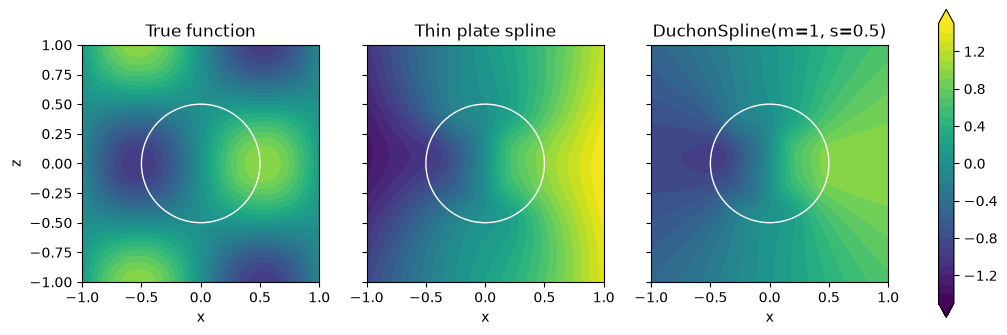

In [3]:
def f(x, z):
    """True function of two variables."""
    return np.sin(3 * x) * np.cos(3 * z)


n = 300
radius = 0.5 * np.sqrt(rng.uniform(0, 1, n))  # Uniform over the disc
angle = rng.uniform(0, 2 * np.pi, n)
x, z = radius * np.cos(angle), radius * np.sin(angle)
data2d = pd.DataFrame({"x": x, "z": z, "y": f(x, z) + rng.normal(scale=0.1, size=n)})

models = {
    "Thin plate spline": GAM({"y": S("x", "z")}),
    "DuchonSpline(m=1, s=0.5)": GAM({"y": S("x", "z", bs=DuchonSpline(m=1, s=0.5))}),
}
x_grid, z_grid = np.meshgrid(np.linspace(-1, 1, 101), np.linspace(-1, 1, 101))
surfaces = {"True function": f(x_grid, z_grid)}
for name, gam in models.items():
    gam.fit(data2d)
    pred = gam.predict({"x": x_grid.ravel(), "z": z_grid.ravel()})["y"]
    surfaces[name] = pred.reshape(x_grid.shape)

levels = np.linspace(-1.5, 1.5, 31)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, surface) in zip(axes, surfaces.items(), strict=True):
    contours = ax.contourf(x_grid, z_grid, surface, levels=levels, extend="both")
    ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="white"))
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_aspect("equal")
axes[0].set_ylabel("z")
fig.colorbar(contours, ax=axes)
plt.show()

The white circle shows the region with data, where both fits are similar. Outside
it, there is no information about the true function, so neither fit can recover it.
However, the thin plate spline keeps increasing or decreasing along straight lines,
while the Duchon spline levels off, which is often a safer behaviour when predicting
away from the data.

!!! tip

    For $d$ variables, a [`DuchonSpline`][pymgcv.basis_functions.DuchonSpline]
    requires $-d/2 < s < d/2$, and gives continuous functions if $m + s > d/2$. With
    `s=0`, it is the usual thin plate spline.